In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Set style for all visualizations
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (16, 10)
plt.rcParams['font.size'] = 11

# Load the dataset
df = pd.read_csv("nvidia_stock_data_1999_2026.csv")
df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y')
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df['daily_return'] = df['close'].pct_change() * 100

era_mapping = {
    'Pre-GPU Era': 'Pre-GPU (1999-2005)',
    'Gaming GPU Era': 'Gaming GPU (2006-2015)',
    'Deep Learning Era': 'Deep Learning (2016-2022)',
    'Data Center Growth': 'Data Center (2023-2024)',
    'Generative AI Era': 'Gen AI (2025-2026)'
}
df['era_label'] = df['era'].map(era_mapping)

print("✅ Data loaded successfully")
print(f"📊 Dataset: {len(df):,} trading days from {df['date'].min().year} to {df['date'].max().year}")

✅ Data loaded successfully
📊 Dataset: 7,079 trading days from 1999 to 2026


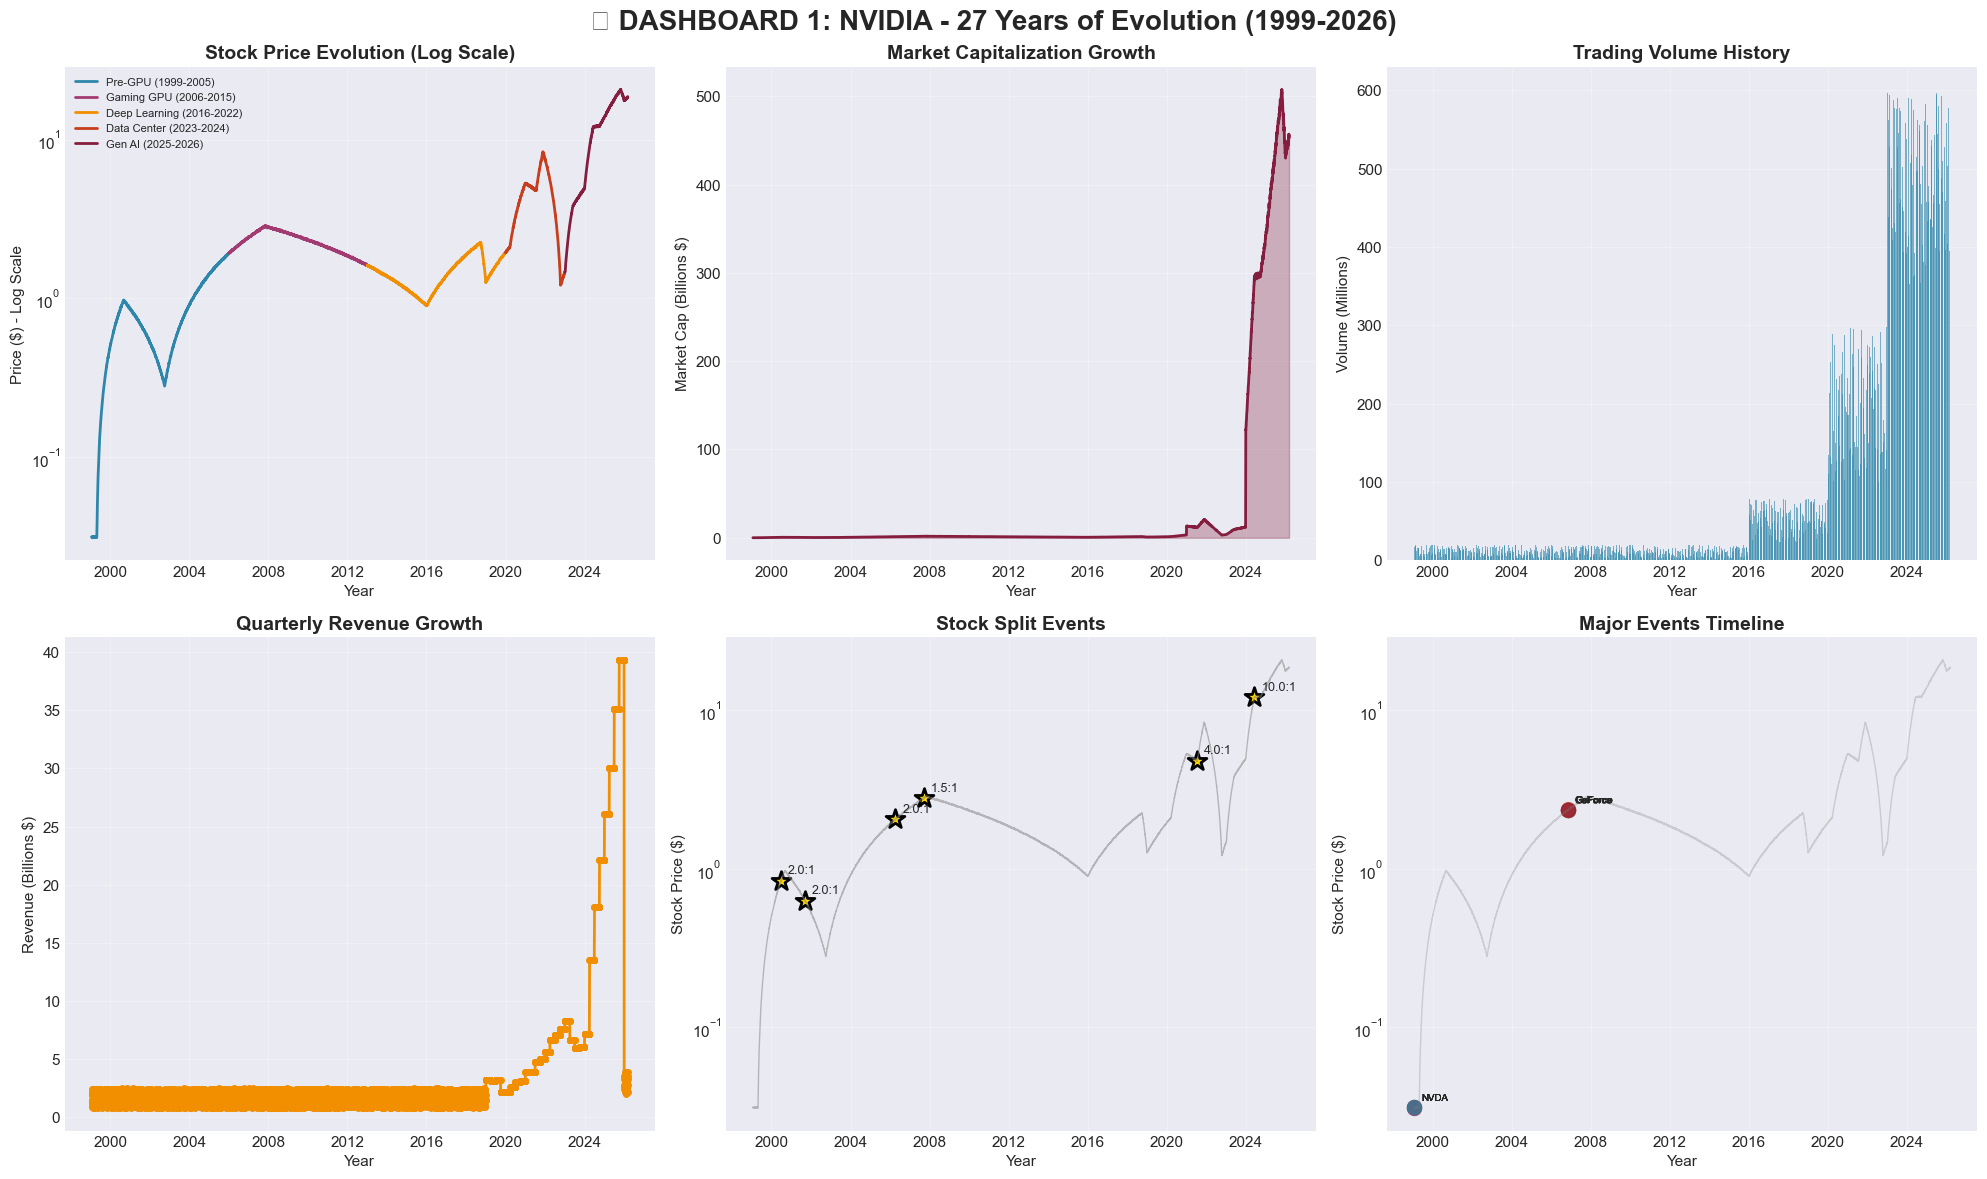

In [3]:
fig = plt.figure(figsize=(20, 12))
fig.suptitle('🚀 DASHBOARD 1: NVIDIA - 27 Years of Evolution (1999-2026)', 
             fontsize=20, fontweight='bold', y=0.98)

# Define color scheme
colors = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#851E3E']

# 1.1 Stock Price Evolution (Log Scale)
ax1 = plt.subplot(2, 3, 1)
for i, era in enumerate(df['era'].unique()):
    era_data = df[df['era'] == era]
    ax1.plot(era_data['date'], era_data['close'], 
             color=colors[i], linewidth=2, label=era_mapping[era])
ax1.set_title('Stock Price Evolution (Log Scale)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Year')
ax1.set_ylabel('Price ($) - Log Scale')
ax1.set_yscale('log')
ax1.legend(fontsize=8, loc='upper left')
ax1.grid(True, alpha=0.3)


# 1.2 Market Cap Growth
ax2 = plt.subplot(2, 3, 2)
ax2.plot(df['date'], df['market_cap_usd_bn'], color=colors[4], linewidth=2)
ax2.fill_between(df['date'], 0, df['market_cap_usd_bn'], alpha=0.3, color=colors[4])
ax2.set_title('Market Capitalization Growth', fontsize=14, fontweight='bold')
ax2.set_xlabel('Year')
ax2.set_ylabel('Market Cap (Billions $)')
ax2.grid(True, alpha=0.3)

# 1.3 Trading Volume Over Time
ax3 = plt.subplot(2, 3, 3)
ax3.bar(df['date'], df['volume']/1e6, color=colors[0], alpha=0.6, width=2)
ax3.set_title('Trading Volume History', fontsize=14, fontweight='bold')
ax3.set_xlabel('Year')
ax3.set_ylabel('Volume (Millions)')
ax3.grid(True, alpha=0.3)

# 1.4 Quarterly Revenue
ax4 = plt.subplot(2, 3, 4)
revenue_data = df.dropna(subset=['quarterly_revenue_usd_bn'])
ax4.plot(revenue_data['date'], revenue_data['quarterly_revenue_usd_bn'], 
         color=colors[2], linewidth=2, marker='o', markersize=4)
ax4.set_title('Quarterly Revenue Growth', fontsize=14, fontweight='bold')
ax4.set_xlabel('Year')
ax4.set_ylabel('Revenue (Billions $)')
ax4.grid(True, alpha=0.3)

# 1.5 Stock Split Events
ax5 = plt.subplot(2, 3, 5)
splits = df[df['stock_split'].notna()]
ax5.plot(df['date'], df['close'], color='gray', alpha=0.5, linewidth=1)
for idx, row in splits.iterrows():
    ax5.scatter(row['date'], row['close'], s=200, color='gold', 
                edgecolor='black', linewidth=2, marker='*')
    ax5.annotate(f"{row['stock_split']}:1", (row['date'], row['close']),
                xytext=(5, 5), textcoords='offset points', fontsize=9)
ax5.set_title('Stock Split Events', fontsize=14, fontweight='bold')
ax5.set_xlabel('Year')
ax5.set_ylabel('Stock Price ($)')
ax5.set_yscale('log')
ax5.grid(True, alpha=0.3)

# 1.6 Key Events Timeline
ax6 = plt.subplot(2, 3, 6)
events = df[df['key_event'].notna() & (df['key_event'] != '')]
ax6.plot(df['date'], df['close'], color='gray', alpha=0.3, linewidth=1)
for i, (idx, row) in enumerate(events.iterrows()):
    if i < 15:  # Show only first 15 events to avoid clutter
        ax6.scatter(row['date'], row['close'], s=100, color=colors[i%5], alpha=0.7)
        ax6.annotate(row['key_event'].split(' ')[0], (row['date'], row['close']),
                    xytext=(5, 5), textcoords='offset points', fontsize=7)
ax6.set_title('Major Events Timeline', fontsize=14, fontweight='bold')
ax6.set_xlabel('Year')
ax6.set_ylabel('Stock Price ($)')
ax6.set_yscale('log')
ax6.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('dashboard1_big_picture.png', dpi=150, bbox_inches='tight')
plt.show()

##  Era-by-Era Performance Analysis Comparing the Five Distinct Phases

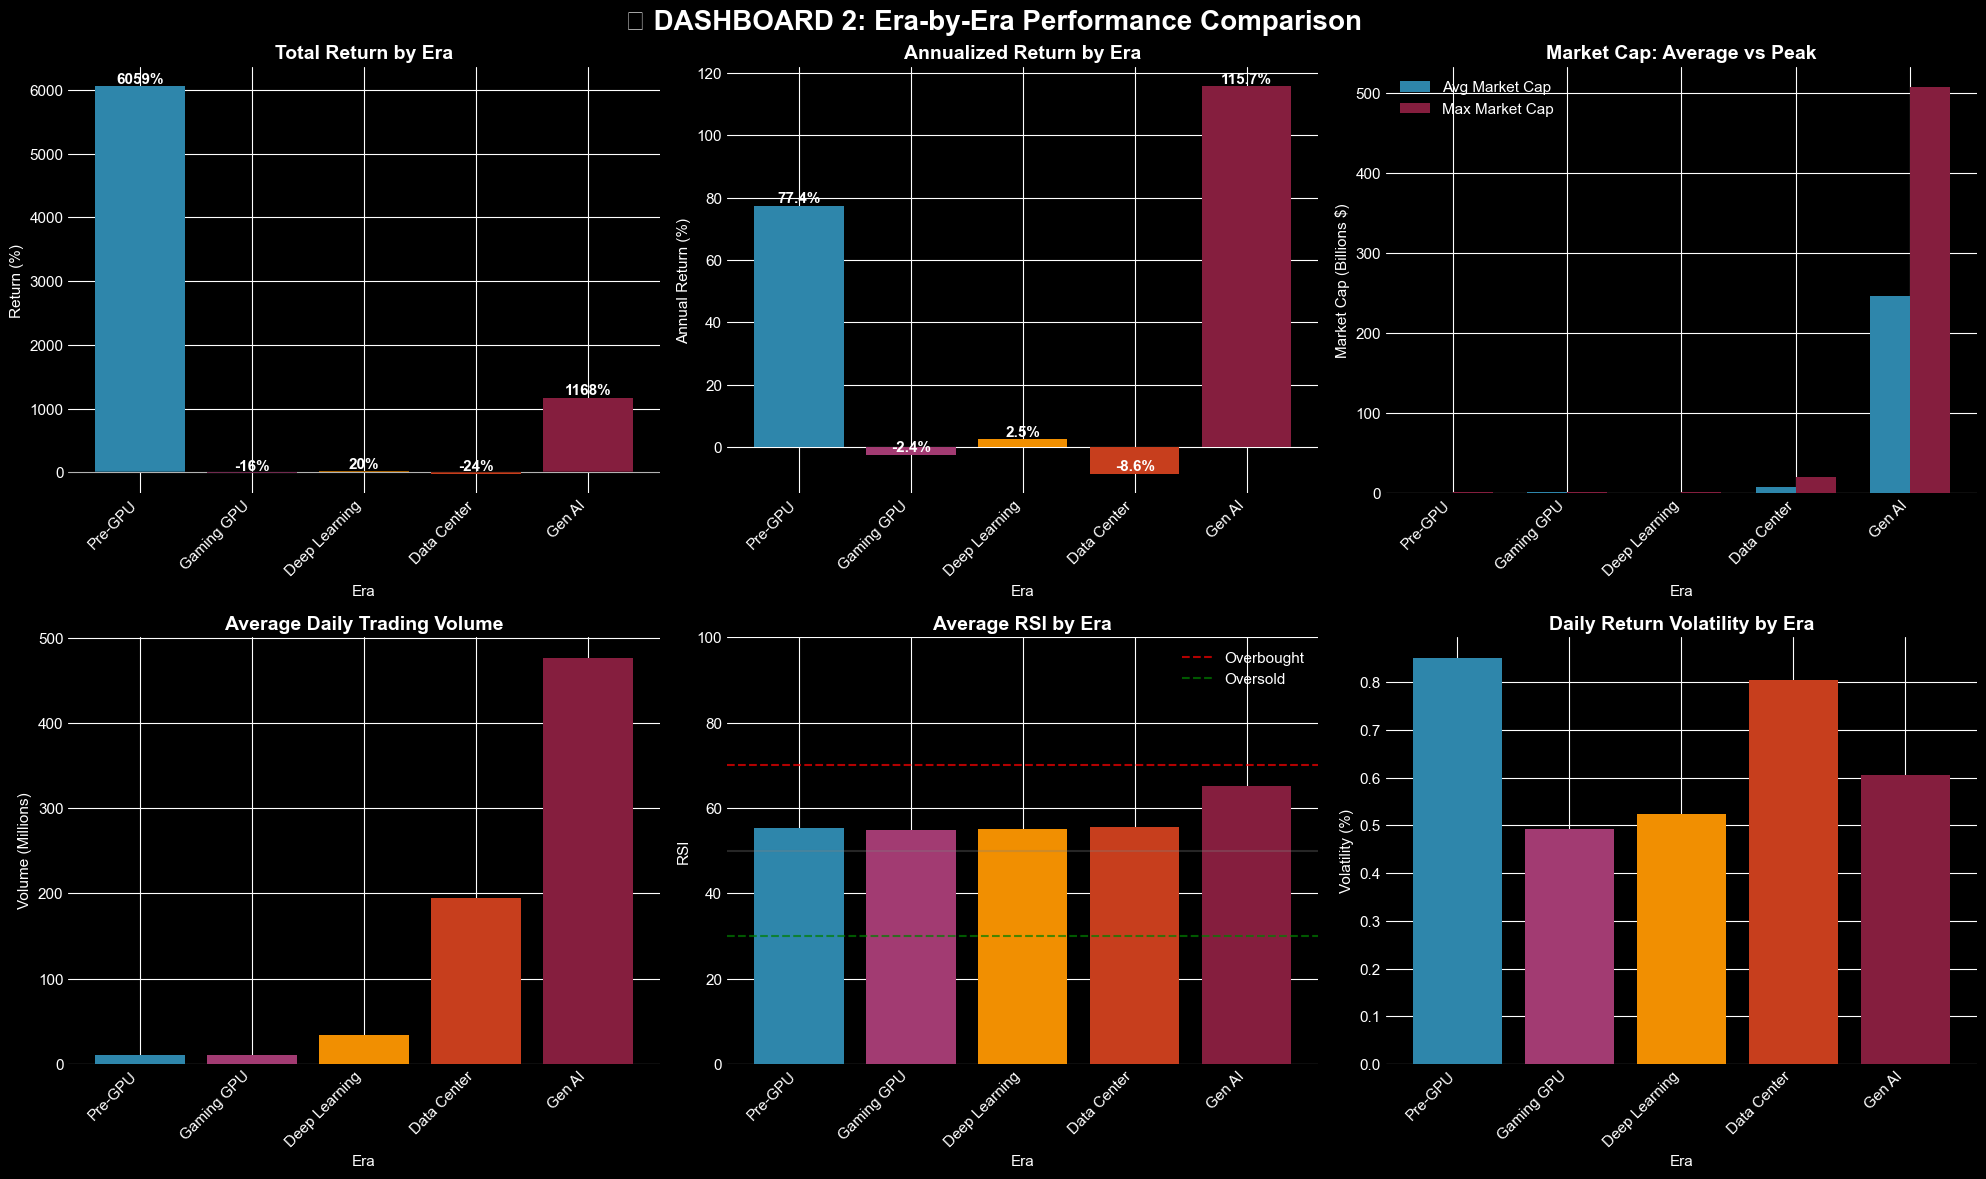

In [7]:
fig = plt.figure(figsize=(20, 12))
fig.suptitle('📊 DASHBOARD 2: Era-by-Era Performance Comparison', 
             fontsize=20, fontweight='bold', y=0.98)

# Prepare era summary data
era_summary = []
for era in df['era'].unique():
    era_data = df[df['era'] == era]
    if len(era_data) > 0:
        era_summary.append({
            'era': era_mapping[era],
            'start_price': era_data.iloc[0]['close'],
            'end_price': era_data.iloc[-1]['close'],
            'return': (era_data.iloc[-1]['close'] / era_data.iloc[0]['close'] - 1) * 100,
            'annual_return': ((era_data.iloc[-1]['close'] / era_data.iloc[0]['close']) ** (1/(len(era_data)/252)) - 1) * 100,
            'avg_mcap': era_data['market_cap_usd_bn'].mean(),
            'max_mcap': era_data['market_cap_usd_bn'].max(),
            'avg_volume': era_data['volume'].mean() / 1e6,
            'avg_rsi': era_data['rsi_14'].mean(),
            'volatility': era_data['daily_return'].std()
        })
era_df = pd.DataFrame(era_summary)


# 2.1 Total Return by Era (Bar Chart)
ax1 = plt.subplot(2, 3, 1)
bars = ax1.bar(range(len(era_df)), era_df['return'], color=colors)
ax1.set_title('Total Return by Era', fontsize=14, fontweight='bold')
ax1.set_xlabel('Era')
ax1.set_ylabel('Return (%)')
ax1.set_xticks(range(len(era_df)))
ax1.set_xticklabels([e.split('(')[0].strip() for e in era_df['era']], rotation=45, ha='right')
for i, bar in enumerate(bars):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.0f}%', ha='center', va='bottom', fontweight='bold')
ax1.axhline(y=0, color='black', linestyle='-', alpha=0.3)

# 2.2 Annualized Return by Era
ax2 = plt.subplot(2, 3, 2)
bars = ax2.bar(range(len(era_df)), era_df['annual_return'], color=colors)
ax2.set_title('Annualized Return by Era', fontsize=14, fontweight='bold')
ax2.set_xlabel('Era')
ax2.set_ylabel('Annual Return (%)')
ax2.set_xticks(range(len(era_df)))
ax2.set_xticklabels([e.split('(')[0].strip() for e in era_df['era']], rotation=45, ha='right')
for i, bar in enumerate(bars):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.1f}%', ha='center', va='bottom', fontweight='bold')

# 2.3 Market Cap Comparison
ax3 = plt.subplot(2, 3, 3)
x = np.arange(len(era_df))
width = 0.35
bars3a = ax3.bar(x - width/2, era_df['avg_mcap'], width, label='Avg Market Cap', color=colors[0])
bars3b = ax3.bar(x + width/2, era_df['max_mcap'], width, label='Max Market Cap', color=colors[4])
ax3.set_title('Market Cap: Average vs Peak', fontsize=14, fontweight='bold')
ax3.set_xlabel('Era')
ax3.set_ylabel('Market Cap (Billions $)')
ax3.set_xticks(x)
ax3.set_xticklabels([e.split('(')[0].strip() for e in era_df['era']], rotation=45, ha='right')
ax3.legend()

# 2.4 Trading Volume by Era
ax4 = plt.subplot(2, 3, 4)
bars = ax4.bar(range(len(era_df)), era_df['avg_volume'], color=colors)
ax4.set_title('Average Daily Trading Volume', fontsize=14, fontweight='bold')
ax4.set_xlabel('Era')
ax4.set_ylabel('Volume (Millions)')
ax4.set_xticks(range(len(era_df)))
ax4.set_xticklabels([e.split('(')[0].strip() for e in era_df['era']], rotation=45, ha='right')

# 2.5 RSI Analysis by Era
ax5 = plt.subplot(2, 3, 5)
bars = ax5.bar(range(len(era_df)), era_df['avg_rsi'], color=colors)
ax5.axhline(y=70, color='red', linestyle='--', alpha=0.7, label='Overbought')
ax5.axhline(y=50, color='gray', linestyle='-', alpha=0.3)
ax5.axhline(y=30, color='green', linestyle='--', alpha=0.7, label='Oversold')
ax5.set_title('Average RSI by Era', fontsize=14, fontweight='bold')
ax5.set_xlabel('Era')
ax5.set_ylabel('RSI')
ax5.set_xticks(range(len(era_df)))
ax5.set_xticklabels([e.split('(')[0].strip() for e in era_df['era']], rotation=45, ha='right')
ax5.set_ylim(0, 100)
ax5.legend()

# 2.6 Volatility by Era
ax6 = plt.subplot(2, 3, 6)
bars = ax6.bar(range(len(era_df)), era_df['volatility'], color=colors)
ax6.set_title('Daily Return Volatility by Era', fontsize=14, fontweight='bold')
ax6.set_xlabel('Era')
ax6.set_ylabel('Volatility (%)')
ax6.set_xticks(range(len(era_df)))
ax6.set_xticklabels([e.split('(')[0].strip() for e in era_df['era']], rotation=45, ha='right')

plt.tight_layout()
plt.savefig('dashboard2_era_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


## Technical Indicators Deep Dive RSI, Moving Averages, and Trading Patterns

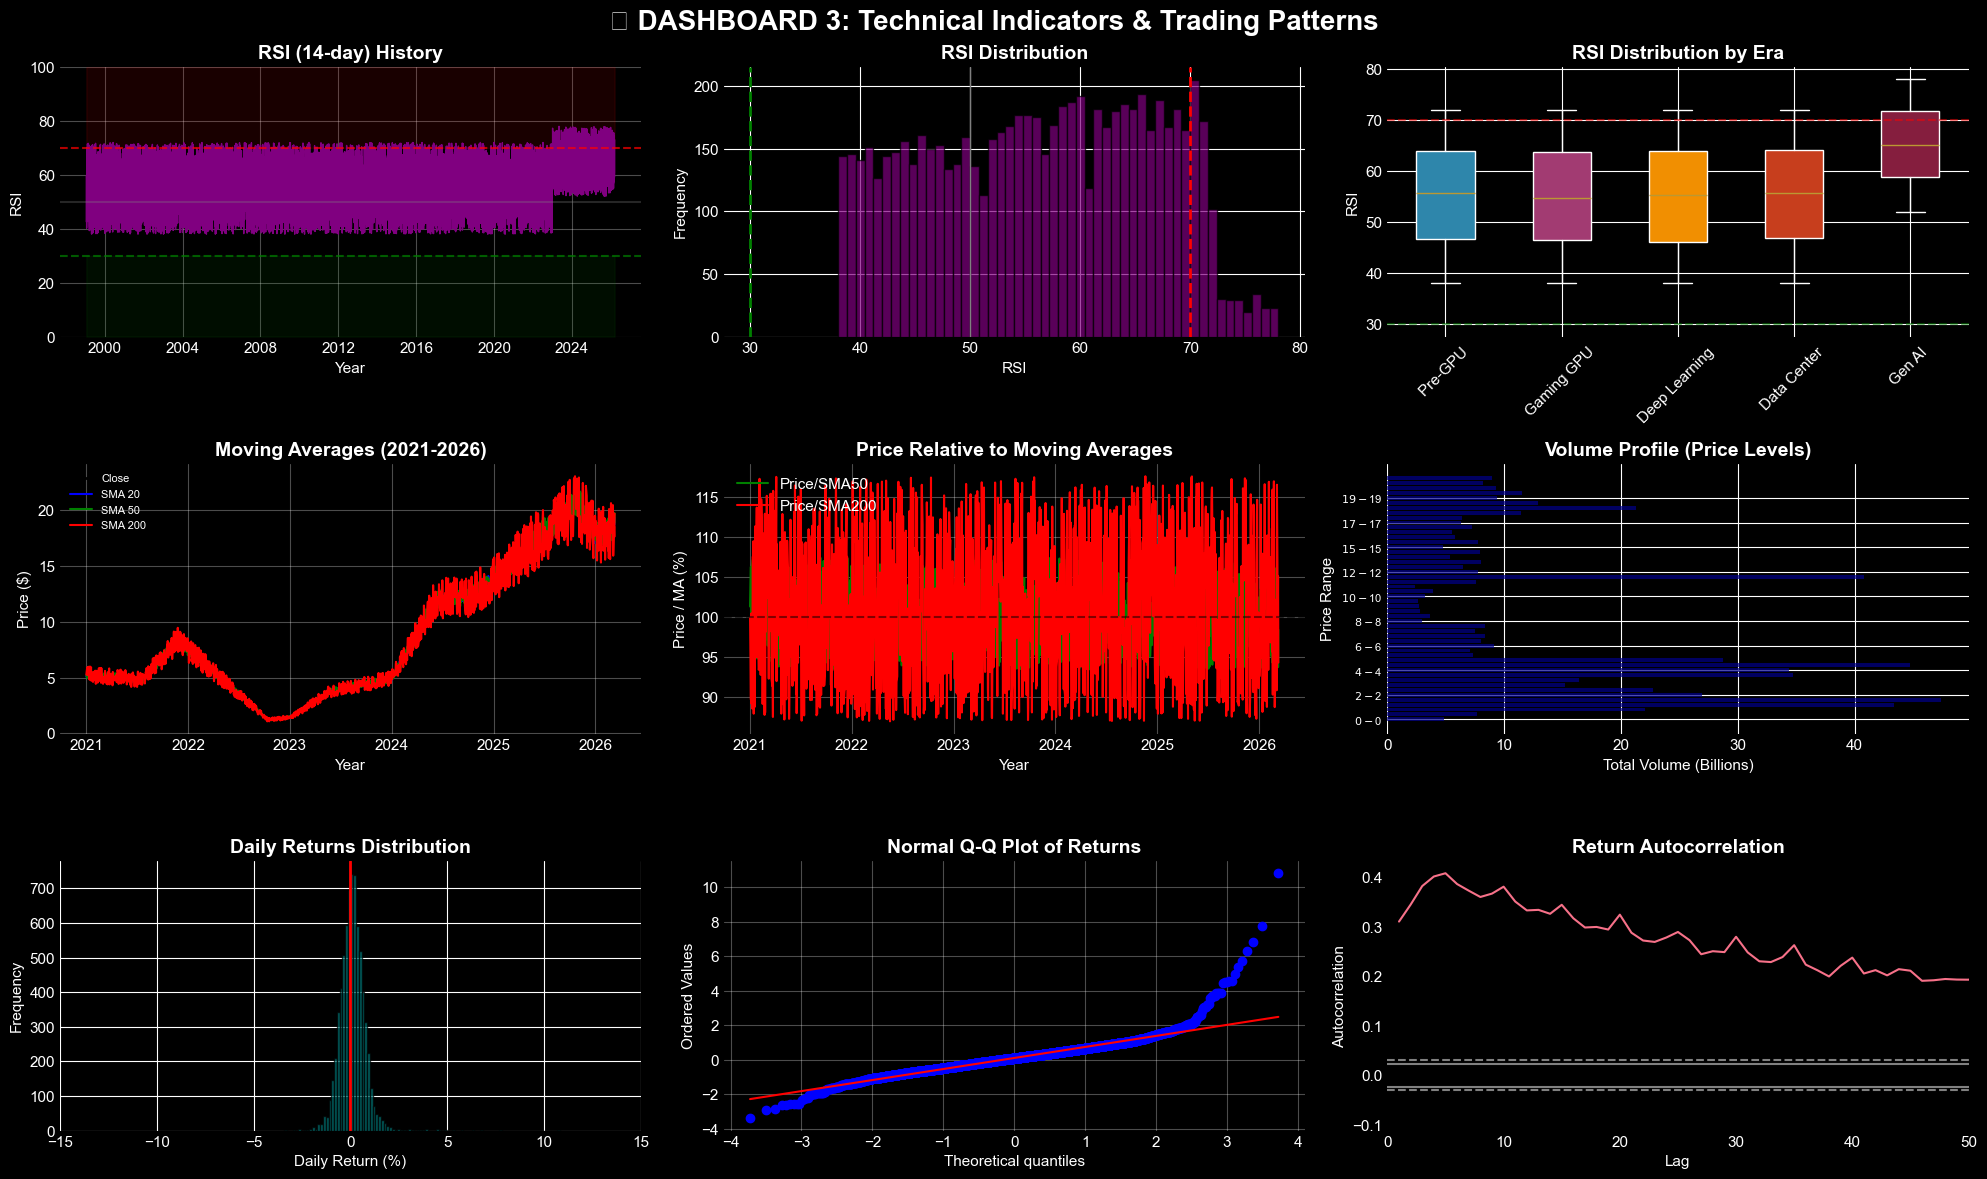

In [8]:
fig = plt.figure(figsize=(20, 12))
fig.suptitle('📈 DASHBOARD 3: Technical Indicators & Trading Patterns', 
             fontsize=20, fontweight='bold', y=0.98)

# 3.1 RSI History with Zones
ax1 = plt.subplot(3, 3, 1)
ax1.plot(df['date'], df['rsi_14'], color='purple', linewidth=1)
ax1.axhline(y=70, color='red', linestyle='--', linewidth=1.5, alpha=0.7)
ax1.axhline(y=30, color='green', linestyle='--', linewidth=1.5, alpha=0.7)
ax1.axhline(y=50, color='gray', linestyle='-', alpha=0.3)
ax1.fill_between(df['date'], 70, 100, alpha=0.1, color='red')
ax1.fill_between(df['date'], 0, 30, alpha=0.1, color='green')
ax1.set_title('RSI (14-day) History', fontsize=14, fontweight='bold')
ax1.set_xlabel('Year')
ax1.set_ylabel('RSI')
ax1.set_ylim(0, 100)
ax1.grid(True, alpha=0.3)


# 3.2 RSI Distribution
ax2 = plt.subplot(3, 3, 2)
ax2.hist(df['rsi_14'].dropna(), bins=50, color='purple', alpha=0.7, edgecolor='black')
ax2.axvline(x=70, color='red', linestyle='--', linewidth=2)
ax2.axvline(x=50, color='gray', linestyle='-', linewidth=1)
ax2.axvline(x=30, color='green', linestyle='--', linewidth=2)
ax2.set_title('RSI Distribution', fontsize=14, fontweight='bold')
ax2.set_xlabel('RSI')
ax2.set_ylabel('Frequency')

# 3.3 RSI by Era (Box Plot)
ax3 = plt.subplot(3, 3, 3)
rsi_by_era = [df[df['era'] == era]['rsi_14'].dropna().values for era in df['era'].unique()]
bp = ax3.boxplot(rsi_by_era, patch_artist=True, labels=[e.split('(')[0] for e in era_mapping.values()])
for i, box in enumerate(bp['boxes']):
    box.set_facecolor(colors[i % len(colors)])
ax3.axhline(y=70, color='red', linestyle='--', alpha=0.5)
ax3.axhline(y=30, color='green', linestyle='--', alpha=0.5)
ax3.set_title('RSI Distribution by Era', fontsize=14, fontweight='bold')
ax3.set_ylabel('RSI')
ax3.tick_params(axis='x', rotation=45)

# 3.4 Moving Averages (Last 5 Years)
ax4 = plt.subplot(3, 3, 4)
recent = df[df['date'] >= '2021-01-01'].copy()
ax4.plot(recent['date'], recent['close'], color='black', linewidth=2, label='Close')
ax4.plot(recent['date'], recent['sma_20'], color='blue', linewidth=1.5, label='SMA 20')
ax4.plot(recent['date'], recent['sma_50'], color='green', linewidth=1.5, label='SMA 50')
ax4.plot(recent['date'], recent['sma_200'], color='red', linewidth=1.5, label='SMA 200')
ax4.set_title('Moving Averages (2021-2026)', fontsize=14, fontweight='bold')
ax4.set_xlabel('Year')
ax4.set_ylabel('Price ($)')
ax4.legend(loc='upper left', fontsize=8)
ax4.grid(True, alpha=0.3)

# 3.5 Price vs SMA Ratios
ax5 = plt.subplot(3, 3, 5)
ax5.plot(recent['date'], recent['close']/recent['sma_50']*100, color='green', linewidth=1.5, label='Price/SMA50')
ax5.plot(recent['date'], recent['close']/recent['sma_200']*100, color='red', linewidth=1.5, label='Price/SMA200')
ax5.axhline(y=100, color='black', linestyle='--', alpha=0.5)
ax5.set_title('Price Relative to Moving Averages', fontsize=14, fontweight='bold')
ax5.set_xlabel('Year')
ax5.set_ylabel('Price / MA (%)')
ax5.legend()
ax5.grid(True, alpha=0.3)


# 3.6 Volume Profile
ax6 = plt.subplot(3, 3, 6)
volume_by_price = df.groupby(pd.cut(df['close'], bins=50))['volume'].sum() / 1e9
ax6.barh(range(len(volume_by_price)), volume_by_price.values, color='darkblue', alpha=0.7)
ax6.set_title('Volume Profile (Price Levels)', fontsize=14, fontweight='bold')
ax6.set_xlabel('Total Volume (Billions)')
ax6.set_ylabel('Price Range')
ax6.set_yticks(range(0, len(volume_by_price), 5))
ax6.set_yticklabels([f'${b:.0f}-${b:.0f}' for b in volume_by_price.index.categories.left[::5]], fontsize=8)

# 3.7 Daily Returns Distribution
ax7 = plt.subplot(3, 3, 7)
ax7.hist(df['daily_return'].dropna(), bins=100, color='teal', alpha=0.7, edgecolor='black')
ax7.axvline(x=0, color='red', linestyle='-', linewidth=2)
ax7.set_title('Daily Returns Distribution', fontsize=14, fontweight='bold')
ax7.set_xlabel('Daily Return (%)')
ax7.set_ylabel('Frequency')
ax7.set_xlim(-15, 15)


# 3.8 Returns QQ Plot
ax8 = plt.subplot(3, 3, 8)
from scipy import stats
stats.probplot(df['daily_return'].dropna(), dist="norm", plot=ax8)
ax8.set_title('Normal Q-Q Plot of Returns', fontsize=14, fontweight='bold')
ax8.grid(True, alpha=0.3)

# 3.9 Autocorrelation of Returns
ax9 = plt.subplot(3, 3, 9)
pd.plotting.autocorrelation_plot(df['daily_return'].dropna(), ax=ax9)
ax9.set_title('Return Autocorrelation', fontsize=14, fontweight='bold')
ax9.set_xlim(0, 50)

plt.tight_layout()
plt.savefig('dashboard3_technical_indicators.png', dpi=150, bbox_inches='tight')
plt.show()

## The Generative AI Era (2023–2026)  The Explosive Growth Phase

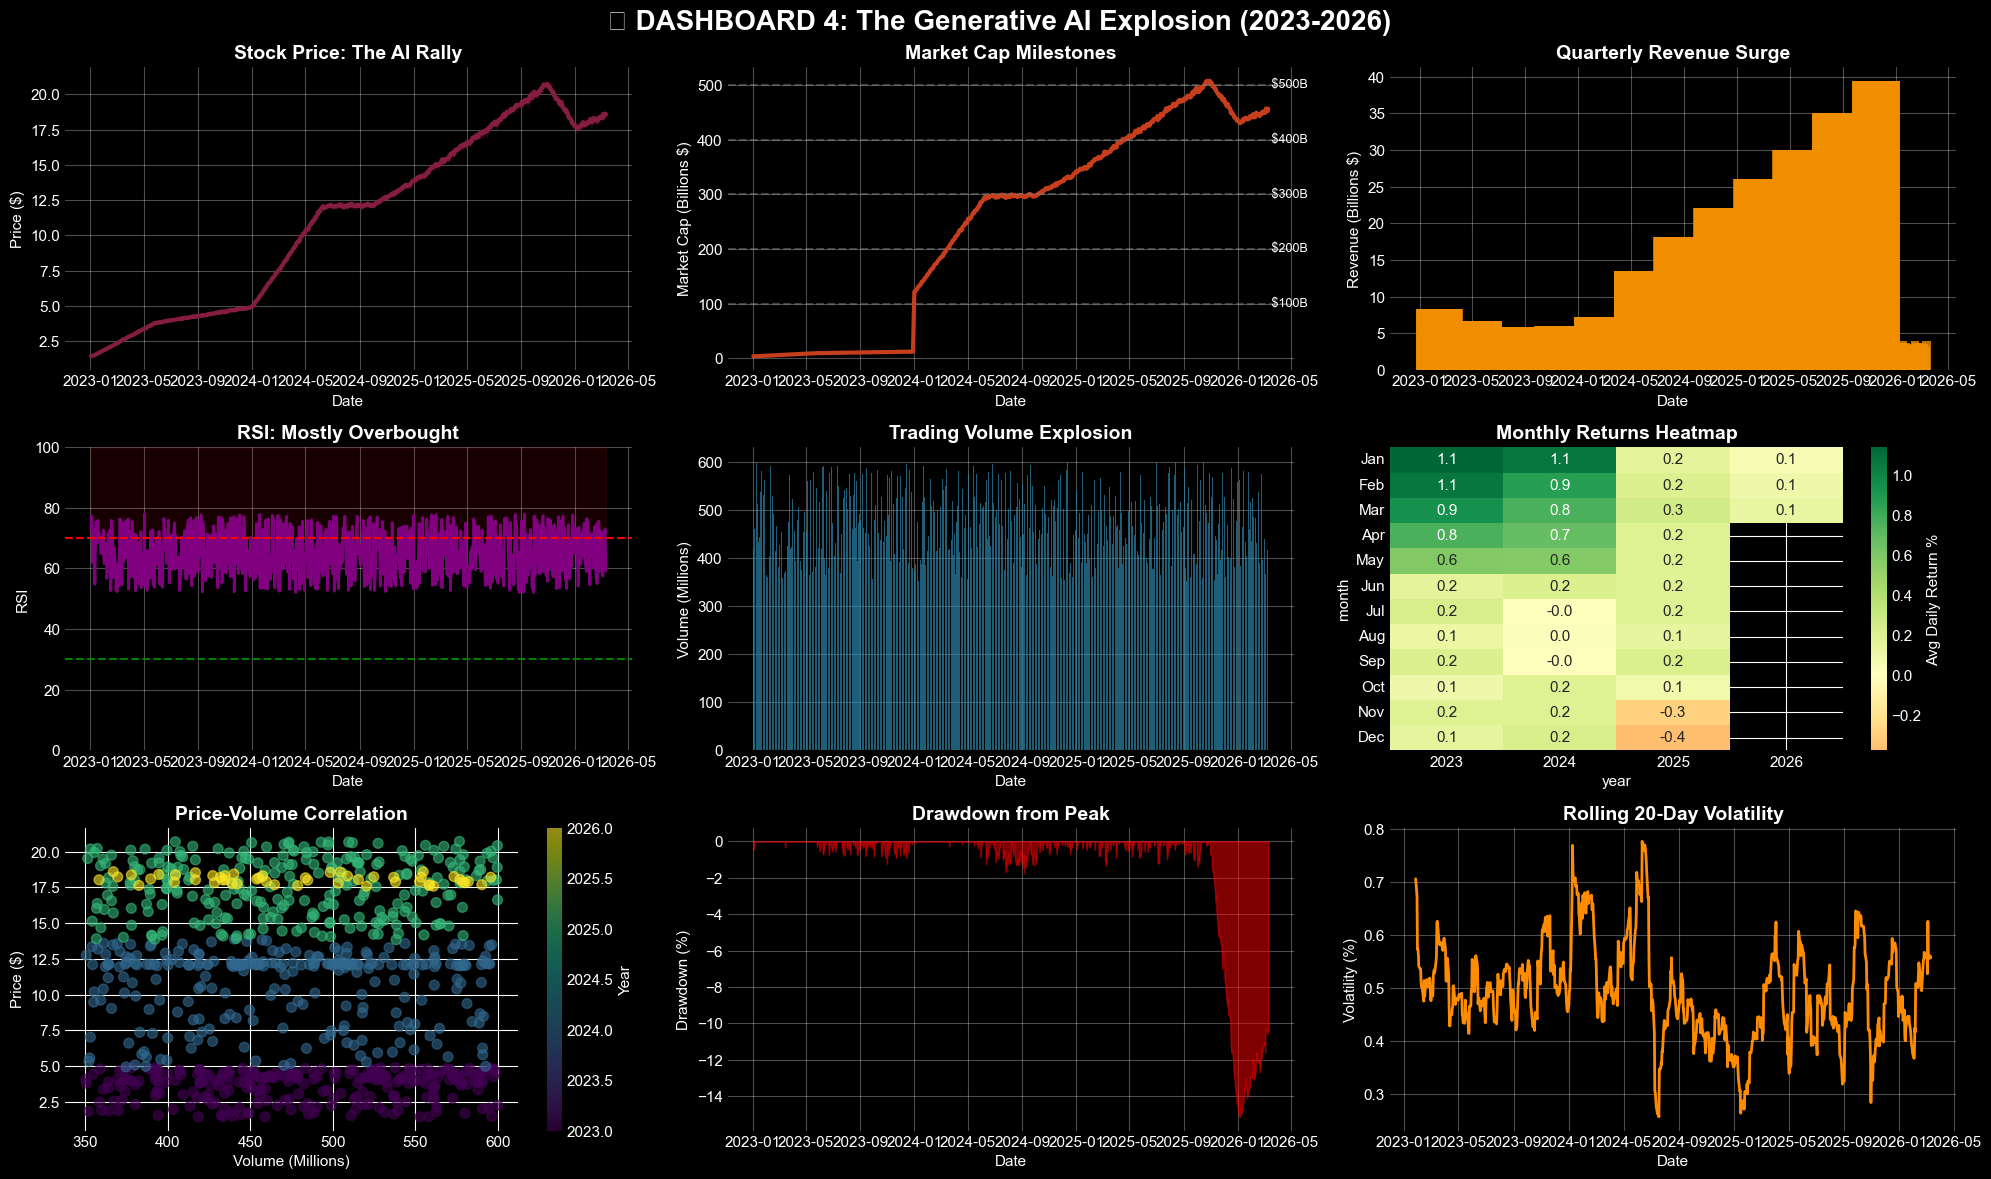

In [9]:
fig = plt.figure(figsize=(20, 12))
fig.suptitle('🤖 DASHBOARD 4: The Generative AI Explosion (2023-2026)', 
             fontsize=20, fontweight='bold', y=0.98)

# Filter recent data
ai_era = df[df['date'] >= '2023-01-01'].copy()
ai_era['month_year'] = ai_era['date'].dt.to_period('M')

# 4.1 Price Explosion
ax1 = plt.subplot(3, 3, 1)
ax1.plot(ai_era['date'], ai_era['close'], color='#851E3E', linewidth=3)
ax1.fill_between(ai_era['date'], ai_era['low'], ai_era['high'], alpha=0.2, color='#851E3E')
ax1.set_title('Stock Price: The AI Rally', fontsize=14, fontweight='bold')
ax1.set_xlabel('Date')
ax1.set_ylabel('Price ($)')
ax1.grid(True, alpha=0.3)

# 4.2 Market Cap Milestones
ax2 = plt.subplot(3, 3, 2)
ax2.plot(ai_era['date'], ai_era['market_cap_usd_bn'], color='#C73E1D', linewidth=3)
milestones = [100, 200, 300, 400, 500]
for m in milestones:
    if m <= ai_era['market_cap_usd_bn'].max():
        date_reached = ai_era[ai_era['market_cap_usd_bn'] >= m]['date'].iloc[0]
        ax2.axhline(y=m, color='gray', linestyle='--', alpha=0.5)
        ax2.text(ai_era['date'].iloc[-1], m, f' ${m}B', va='center', fontsize=9)
ax2.set_title('Market Cap Milestones', fontsize=14, fontweight='bold')
ax2.set_xlabel('Date')
ax2.set_ylabel('Market Cap (Billions $)')
ax2.grid(True, alpha=0.3)

# 4.3 Revenue Explosion
ax3 = plt.subplot(3, 3, 3)
rev_ai = ai_era.dropna(subset=['quarterly_revenue_usd_bn'])
ax3.bar(rev_ai['date'], rev_ai['quarterly_revenue_usd_bn'], width=20, color='#F18F01', alpha=0.8)
ax3.set_title('Quarterly Revenue Surge', fontsize=14, fontweight='bold')
ax3.set_xlabel('Date')
ax3.set_ylabel('Revenue (Billions $)')
ax3.grid(True, alpha=0.3)

# 4.4 RSI in AI Era
ax4 = plt.subplot(3, 3, 4)
ax4.plot(ai_era['date'], ai_era['rsi_14'], color='purple', linewidth=2)
ax4.axhline(y=70, color='red', linestyle='--')
ax4.axhline(y=30, color='green', linestyle='--')
ax4.fill_between(ai_era['date'], 70, 100, alpha=0.1, color='red')
ax4.set_title('RSI: Mostly Overbought', fontsize=14, fontweight='bold')
ax4.set_xlabel('Date')
ax4.set_ylabel('RSI')
ax4.set_ylim(0, 100)
ax4.grid(True, alpha=0.3)

# 4.5 Volume Surge
ax5 = plt.subplot(3, 3, 5)
ax5.bar(ai_era['date'], ai_era['volume']/1e6, color='#2E86AB', alpha=0.7, width=1)
ax5.set_title('Trading Volume Explosion', fontsize=14, fontweight='bold')
ax5.set_xlabel('Date')
ax5.set_ylabel('Volume (Millions)')
ax5.grid(True, alpha=0.3)

# 4.6 Monthly Returns Heatmap
ax6 = plt.subplot(3, 3, 6)
ai_era['year'] = ai_era['date'].dt.year
ai_era['month'] = ai_era['date'].dt.month
monthly_returns = ai_era.pivot_table(values='daily_return', index='month', columns='year', aggfunc='mean')
sns.heatmap(monthly_returns, annot=True, fmt='.1f', cmap='RdYlGn', center=0, 
            xticklabels=monthly_returns.columns, yticklabels=['Jan','Feb','Mar','Apr','May','Jun',
                                                              'Jul','Aug','Sep','Oct','Nov','Dec'],
            ax=ax6, cbar_kws={'label': 'Avg Daily Return %'})
ax6.set_title('Monthly Returns Heatmap', fontsize=14, fontweight='bold')

# 4.7 Price vs Volume Correlation
ax7 = plt.subplot(3, 3, 7)
sc = ax7.scatter(ai_era['volume']/1e6, ai_era['close'], 
                 c=ai_era['date'].dt.year, cmap='viridis', s=50, alpha=0.6)
ax7.set_title('Price-Volume Correlation', fontsize=14, fontweight='bold')
ax7.set_xlabel('Volume (Millions)')
ax7.set_ylabel('Price ($)')
plt.colorbar(sc, ax=ax7, label='Year')

# 4.8 Drawdown Analysis
ax8 = plt.subplot(3, 3, 8)
rolling_max = ai_era['close'].cummax()
drawdown = (ai_era['close'] - rolling_max) / rolling_max * 100
ax8.fill_between(ai_era['date'], drawdown, 0, color='red', alpha=0.5)
ax8.set_title('Drawdown from Peak', fontsize=14, fontweight='bold')
ax8.set_xlabel('Date')
ax8.set_ylabel('Drawdown (%)')
ax8.grid(True, alpha=0.3)


# 4.9 Volatility Trend
ax9 = plt.subplot(3, 3, 9)
ai_era['volatility_20d'] = ai_era['daily_return'].rolling(20).std()
ax9.plot(ai_era['date'], ai_era['volatility_20d'], color='darkorange', linewidth=2)
ax9.set_title('Rolling 20-Day Volatility', fontsize=14, fontweight='bold')
ax9.set_xlabel('Date')
ax9.set_ylabel('Volatility (%)')
ax9.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('dashboard4_ai_era.png', dpi=150, bbox_inches='tight')
plt.show()